In [ ]:
'''
Steps of knn
 1 - For each test datapoint, find distances of against all the train points
 2 - Sort low to high distances
 3 - find the majority class of the top k distances

 
Assumptions
1 - homegenous neighbourhood
2 - higher the outliers, more the inaccurate will be the model

bias vs variance in knn:
    - lower the n, lesser has its own opinion , higher the variance, lesser the bias - HENCE OVERFITTING
    - higher the n, more generic is the regression and hence, variance is lower and bias is higher - HENCE UNDERFITTING

 Remember:
    - It is a non parameteric algorithm. there are no weights to do learning 
    - SCALING IS EXTREMELY IMPORTANT FOR KNN because of distance being the fundamental nehind the logic
        for all sets - train, test and val
    - always do one hot encoding to avoid curese of fimensionality - for both train, val and test data
    - for high dimensions, use cosine similarity. It gives equal importance to all the features . manhattan is used when data is like a map
    - logisitic regression needs linearly seperable classes but knn doesnt
    - oversampling should only be applied to ONLY TRAIN SET and not val and test set
        because train and test set should replicate your production environment
    - note that in the below case where we are building our own model, we are evaluating a val case aaginst distances from the train dataset


READ ABOUT LSH - LOCALITY SENSITIVE HASHING

IGNORE THE PCA PART - ITS USELESS IN THIS MODULE


'''

'\nSteps of knn\n 1 - For each test datapoint, find distances of against all the train points\n 2 - Sort low to high distances\n 3 - find the majority class of the top k distances\n\n\nAssumptions\n1 - homegenous neighbourhood\n2 - higher the outliers, more the inaccurate will be the model\n\nbias vs variance in knn:\n    - lower the n, lesser has its own opinion , higher the variance, lesser the bias - HENCE OVERFITTING\n    - higher the n, more generic is the regression and hence, variance is lower and bias is higher - HENCE UNDERFITTING\n\n Remember:\n    - It is a non parameteric algorithm. there are no weights to do learning \n    - SCALING IS EXTREMELY IMPORTANT FOR KNN because of distance being the fundamental nehind the logic\n        for all sets - train, test and val\n    - always do one hot encoding to avoid curese of fimensionality - for both train, val and test data\n    - for high dimensions, use cosine similarity. It gives equal importance to all the features . manhattan

# Build knn algorithm from scratch

In [18]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np 

In [19]:

df=pd.read_csv(r'C:\Users\Mayank Bhatia\Documents\GitHub\DSML\14_ml_supervised_algorithms\14.1_ml_k_nearest_neighbors_1\multiclass.csv')

In [20]:
df

,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,class
0,3,12669,9656,7561,214,2674,1338,2
1,3,7057,9810,9568,1762,3293,1776,2
2,3,6353,8808,7684,2405,3516,7844,2
3,3,13265,1196,4221,6404,507,1788,1
4,3,22615,5410,7198,3915,1777,5185,1
...,...,...,...,...,...,...,...,...
435,3,29703,12051,16027,13135,182,2204,2
436,3,39228,1431,764,4510,93,2346,2
437,3,14531,15488,30243,437,14841,1867,2
438,3,10290,1981,2232,1038,168,2125,3


In [21]:
y=df['class']
x=df.drop(['class'],axis=1)

## Implementation of oversampling


In [22]:
from imblearn.over_sampling import SMOTE

In [23]:

x_mid,x_test,y_mid,y_test=train_test_split(x,y,random_state=42,train_size=0.8)
x_train,x_val,y_train,y_val=train_test_split(x_mid,y_mid,random_state=42,train_size=0.8)

In [24]:
smt=SMOTE()
x_train_sm,y_train_sm=smt.fit_resample(x_train,y_train)

In [25]:
print(y_train.value_counts())
print(y_train_sm.value_counts())

class
2    115
3    110
1     56
Name: count, dtype: int64
class
2    115
3    115
1    115
Name: count, dtype: int64


## Scaling

In [26]:
scale=StandardScaler()
x_train_sm_scaled=scale.fit_transform(x_train_sm)
x_val_scaled=scale.transform(x_val)
x_test_scaled=scale.transform(x_test)

## Applying KNN for a singular point (50th point)

In [27]:
x_point=x_val_scaled[50]

In [28]:
x_train_sm_scaled.shape[0]

345

In [29]:
distances=[]
for i in np.arange(x_train_sm_scaled.shape[0]):
    dist=np.sqrt(np.sum((x_point-x_train_sm_scaled[i])**2))
    distances.append(dist)



In [30]:

dist_df=pd.DataFrame({'dist':distances,'class':y_train_sm})
dist_df_2=dist_df.sort_values(by='dist')
# here, class will be 2 for k=3 and will be 1 for k=5

In [31]:
dist_df_2.head()

,dist,class
24,0.830733,1
302,0.853446,1
282,0.902795,1
56,0.926764,2
281,0.937957,1


In [32]:
dist_df_2_sliced=dist_df_2[:3]
counts=np.unique(dist_df_2_sliced['class'],return_counts=True)
ind=counts[1].argmax()
counts[0][ind]

np.int64(1)

## Defining a function and then prediciting for all the points

In [38]:
def pred_knn(x,y,point,k):
    distances=[]
    for i in np.arange(x.shape[0]):
        dist=np.sqrt(np.sum((point-x[i])**2))
        distances.append(dist)
    dist_df=pd.DataFrame({'dist':distances,'class':y})
    dist_df_2=dist_df.sort_values(by='dist')
    dist_df_2_sliced=dist_df_2[:k]
    count=np.unique(dist_df_2_sliced['class'],return_counts=True)
    ind=count[1].argmax()
    pred_value=count[0][ind]
    return pred_value


In [39]:
a=pred_knn(x_train_sm_scaled,y_train_sm,x_val_scaled[50],5)
print(a)

1


### running functions for all the test values

In [40]:
y_test_pred=[]

for i in np.arange(x_test_scaled.shape[0]):
    pred_mid=pred_knn(x_train_sm_scaled,y_train_sm,x_test_scaled[i],5)
    y_test_pred.append(pred_mid)
    

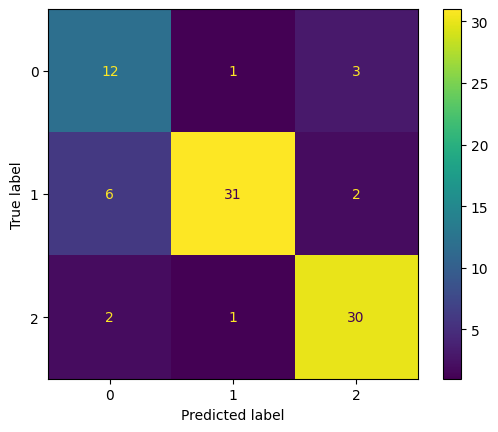

In [41]:
confusion_matrix(y_test,y_test_pred)
ConfusionMatrixDisplay(confusion_matrix(y_test,y_test_pred)).plot()

In [42]:
print(classification_report(y_test,y_test_pred))

              precision    recall  f1-score   support

           1       0.60      0.75      0.67        16
           2       0.94      0.79      0.86        39
           3       0.86      0.91      0.88        33

    accuracy                           0.83        88
   macro avg       0.80      0.82      0.80        88
weighted avg       0.85      0.83      0.83        88

